Импорт данных из csv
Формат: 1 элемент - target

In [85]:
!pip install kornia

In [88]:
import numpy as np
import time
import copy
import os
import random
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
import kornia
import kornia.augmentation as K
import torch.nn as nn

# Читаем CSV в массив NumPy
train_csv = np.loadtxt("mnist_train.csv", delimiter=',')
print(train_csv)

test_csv = np.loadtxt("mnist_test.csv", delimiter=',')
print(test_csv)

[[5. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [4. 0. 0. ... 0. 0. 0.]
 ...
 [5. 0. 0. ... 0. 0. 0.]
 [6. 0. 0. ... 0. 0. 0.]
 [8. 0. 0. ... 0. 0. 0.]]
[[7. 0. 0. ... 0. 0. 0.]
 [2. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [4. 0. 0. ... 0. 0. 0.]
 [5. 0. 0. ... 0. 0. 0.]
 [6. 0. 0. ... 0. 0. 0.]]


Фиксируем сид

In [53]:
def seed_everything(seed: int = 22):
  # Python built-in random
  random.seed(seed)

  # NumPy
  np.random.seed(seed)

  # PyTorch (CPU & CUDA)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)

Отбор меток и нормализация

In [54]:
train_target = train_csv[:, 0].astype(int)
test_target = test_csv[:, 0].astype(int)
train = train_csv[:, 1:]
test = test_csv[:, 1:]

train = (train - np.min(train)) / (np.max(train) - np.min(train))
test = (test - np.min(test)) / (np.max(test) - np.min(test))
train = np.float32(train)
test = np.float32(test)
print(train_target, test_target)
print(test, train)

[5 0 4 ... 5 6 8] [7 2 1 ... 4 5 6]
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]] [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


Перевод на формат тензора

In [55]:
tensor_train = torch.from_numpy(train[:int(len(train)*0.8)])
tensor_val = torch.from_numpy(train[int(len(train)*0.8):])
tensor_test = torch.from_numpy(test)

tensor_train_target = torch.from_numpy(train_target[:int(len(train)*0.8)])
tensor_val_target = torch.from_numpy(train_target[int(len(train)*0.8):])
tensor_test_target = torch.from_numpy(test_target)
print(tensor_train.dtype)
print(tensor_test.dtype)
print(tensor_train_target.dtype)
print(tensor_test_target.dtype)

torch.float32
torch.float32
torch.int64
torch.int64


Аугментация и класс датасета

In [56]:

aug = K.AugmentationSequential(
    K.RandomAffine(degrees=15.0, p=1.0),
    K.RandomPerspective(0.5, p=0.5),
    K.RandomErasing(scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0.0, same_on_batch=False, p=0.5)
)

class MyDataset(Dataset):

  def __init__(self,data,target):
      self.data = data
      self.target = target
      self.transform = transform

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
      return self.data[idx], self.target[idx]

reshape данных для моделей


In [57]:
train_4d = tensor_train.view(len(tensor_train), 1, 28, 28)
val_4d = tensor_val.view(len(tensor_val), 1, 28, 28)
test_4d = tensor_test.view(len(tensor_test), 1, 28, 28)
test_4d[0].shape

torch.Size([1, 28, 28])

Функция обучения и тестов с параметрами

In [58]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def train_model(
    class_model,              #модель для обучение
    learning_rate = 0.001,    #lr для обучение
    epochs = 1,               #кол-во эпох
    train_default = None,     #тренеровочные данные формата тензор
    val_default = None,       #валлидационные данные формата тензор
    test_default = None,      #тестовые данные формата тензор
    train = False,            #если нужно обучение
    test = False,             #если нужен тест
    early_stopping = True,    #флаг early stopping
    patience = 10,            #терпение early stopping
    seed = 22,                #сид
    dynamic_lr = False,       #флаг изменения lr во время обучения
    patience_lr = 5,          #терпени dynamic_lr
    diff_lr = 0.5,            #множитель изменения lr
    ):

    #фиксируем сид + перебираем model (класс или функция для дообучения или полного обучения)
    history = None
    seed_everything(seed)
    if isinstance(class_model, nn.Module) == True:
        model = class_model
    else: model = class_model()
    print(f"available device: {device}")

    #проверка на флаги --> что делать тестировать или обучать
    if train == False and test == False: return print("Нет флагов train или test")

    #обучение
    if train == True:
        #dataloader внутри функции для train и test
        data_default_train = MyDataset(train_default, tensor_train_target)
        dataloader_default_train = DataLoader(
            data_default_train,
            batch_size=256,
            shuffle=True,
            num_workers=2  #в рамках colab
        )

        data_default_val = MyDataset(val_default, tensor_val_target)
        dataloader_default_val = DataLoader(
            data_default_val,
            batch_size=256,
            shuffle=False,
            num_workers=2
        )
        #модель на GPU если имеется, лосс и оптимизатор
        model.to(device)
        model.train()
        loss_func = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

        last_accuracy = 0
        val_loss_best = 1
        all_time = 0
        start_time = time.perf_counter()

        history = {   #метрики
            'epoch': [],
            'train_loss': [],
            'train_accuracy': [],
            'val_loss': [],
            'val_accuracy': [],
            'epoch_time': [],
        }
        # само обучение
        for epoch in range(epochs):
            loss_per_epoch = 0
            for batch in dataloader_default_train:    #функции по одному батчу
                batch[0] = aug(batch[0].to(device))   # [0] - данные, [1] - таргет
                batch[1] = batch[1].to(device)

                optimizer.zero_grad()

                predictions = model(batch[0])

                loss = loss_func(predictions, batch[1])

                loss_per_epoch+=loss.item()

                loss.backward()

                optimizer.step()

            model.eval()  #для сборка метрик (предсказаний)
            with torch.no_grad():     #метрики по валидации
              count_of_values, correct, val_loss_sum = 0, 0, 0

              for batch in dataloader_default_val:  #тот же лоадер только без аугментации
                batch[0] = batch[0].to(device)
                batch[1] = batch[1].to(device)

                correct+= (batch[1]  == torch.max(model(batch[0]), dim=1)[1]).sum().item()
                count_of_values += len(batch[1])
                predictions = model(batch[0])
                val_loss_sum += loss_func(predictions, batch[1]).item()

            accuracy = correct / count_of_values
            val_loss = val_loss_sum / len(dataloader_default_val)

            with torch.no_grad():     #метрики по обучающей выборке
              count_of_values, correct = 0, 0

              for batch in dataloader_default_train:
                batch[0] = batch[0].to(device)
                batch[1] = batch[1].to(device)
                correct+= (batch[1]  == torch.max(model(batch[0]), dim=1)[1]).sum().item()
                count_of_values += len(batch[1])

            accuracy_train = correct / count_of_values
            model.train()
            end_time = time.perf_counter()
            execution_time = end_time - start_time  #время батча
            start_time = time.perf_counter()
            loss_per_epoch = loss_per_epoch/len(dataloader_default_train)
            all_time += execution_time    #общее время

            history['epoch'].append(epoch + 1)  #запись метрик
            history['train_loss'].append(loss_per_epoch)
            history['train_accuracy'].append(accuracy_train)
            history['val_loss'].append(val_loss)
            history['val_accuracy'].append(accuracy)
            history['epoch_time'].append(execution_time)

            print(f"Эпоха {epoch+1}/{epochs}, train_accuracy: {accuracy_train:.4f}, train_loss: {loss_per_epoch:.4f}, accuracy_val: {accuracy:.4f},val_loss:{val_loss:.4f}, learning_rate: {learning_rate}, время: {execution_time:.2f} секунд")

            if early_stopping == True:    #ранняя остановка
                if accuracy>last_accuracy:
                    last_accuracy = accuracy
                    best_model = copy.deepcopy(model)
                    best_epoch = epoch
                    patience_1 = patience
                else:
                    patience_1-=1
                    if patience_1 == 0 :
                        print(f"Досрочное завершение")
                        break

            if dynamic_lr == True:      #уменьшение lr
                if val_loss<val_loss_best:
                    val_loss_best = val_loss
                    patience_2 = patience_lr
                else:
                    patience_2-=1
                    if patience_2 == 0:
                        for group in optimizer.param_groups:    #меняем в оптимизаторе
                              group['lr'] = group['lr'] * diff_lr
                        learning_rate = learning_rate * diff_lr
                        patience_2 = patience_lr

        if early_stopping == True:    #берем лучшую
            model = best_model
            print(f"лучшая модель на эпохе: {best_epoch}, с accuracy: {last_accuracy:.4f} ")
        print(f"Общее время: {all_time:.4f}")

    if test == True:    #если только тесты

        data_default_test = MyDataset(test_default, tensor_test_target) #такой же лоадер без аугментации
        dataloader_default_test = DataLoader(
            data_default_test,
            batch_size=256,
            shuffle=False,
            num_workers=2
        )

        model.to(device)
        model.eval()    #блокируем модель

        with torch.no_grad():
          count_of_values, correct = 0, 0
          for batch in dataloader_default_test:
            batch[0] = batch[0].to(device)
            batch[1] = batch[1].to(device)
            correct+= (batch[1]  == torch.max(model(batch[0]), dim=1)[1]).sum().item()
            count_of_values += len(batch[1])

        accuracy = correct / count_of_values
        print(f"test_accuracy: {accuracy:.4f}")

    return model, history

функция для вывода графиков обучения из history

In [93]:
import matplotlib
import matplotlib.pyplot as plt

def plot_history(history, title=""):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    epochs = history['epoch']

    # лучшая эпоха - максимум точности на val
    best_idx = history['val_accuracy'].index(max(history['val_accuracy']))
    best_epoch = epochs[best_idx]

    ax1.plot(epochs, history['train_loss'], label='train')
    ax1.plot(epochs, history['val_loss'], label='val')
    ax1.axvline(best_epoch, color='gray', linestyle='--', label=f'лучшая эпоха ({best_epoch})')
    ax1.set_xlabel('эпоха')
    ax1.set_ylabel('ошибка')
    ax1.set_title('Ошибка')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(epochs, history['train_accuracy'], label='train')
    ax2.plot(epochs, history['val_accuracy'], label='val')
    ax2.axvline(best_epoch, color='gray', linestyle='--', label=f'лучшая эпоха ({best_epoch})')
    ax2.set_xlabel('эпоха')
    ax2.set_ylabel('точность')
    ax2.set_title('Точность')
    ax2.legend()
    ax2.grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Полносвязная модель - 6 слоёв

In [60]:
class Model_Linear(nn.Module):
  def __init__(self):
    super().__init__()
    self.fl = nn.Flatten()
    self.fc1 = nn.Linear(784, 512)
    self.relu = nn.ReLU()
    self.fc2 = nn.Linear(512, 320)
    self.fc3 = nn.Linear(320, 150)
    self.fc4 = nn.Linear(150, 75)
    self.fc5 = nn.Linear(75, 24)
    self.fc6 = nn.Linear(24, 10)

  def forward(self,x):
    # Задаем логику прохода данных
    x = self.fl(x)
    x = self.fc1(x)
    x = self.relu(x)
    x = self.fc2(x)
    x = self.relu(x)
    x = self.fc3(x)
    x = self.relu(x)
    x = self.fc4(x)
    x = self.relu(x)
    x = self.fc5(x)
    x = self.relu(x)
    x = self.fc6(x)

    return x

Свёрточная модель: 3 сверточных и 2 MaxPooling

In [61]:
class Model_Conv_1(nn.Module):
  def __init__(self):
    super().__init__()
    self.Conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5)
    self.relu = nn.ReLU()
    self.MP2 = nn.MaxPool2d(kernel_size=2)
    self.Conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5)
    self.fl = nn.Flatten()
    self.fc1 = nn.Linear(512,256)
    self.fc2 = nn.Linear(256,10)

  def forward(self,x):
    # Задаем логику прохода данных
    x = self.Conv1(x)     #24X24
    x = self.relu(x)
    x = self.MP2(x)       #12X12
    x = self.Conv2(x)     #8X8
    x = self.relu(x)
    x = self.MP2(x)       #4X4
    x = self.fl(x)        #512
    x = self.fc1(x)
    x = self.relu(x)
    x = self.fc2(x)


    return x

вторая тестовая модель conv

In [62]:
class Model_Conv_2(nn.Module):
  def __init__(self):
    super().__init__()
    self.Conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5, padding=2)
    self.relu = nn.ReLU()
    self.MP2 = nn.MaxPool2d(kernel_size=2)
    self.Conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, padding=2)
    self.Conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2)
    self.fl = nn.Flatten()
    self.fc1 = nn.Linear(576,256)
    self.fc2 = nn.Linear(256,10)
    self.dropout1 = nn.Dropout(p=0.3)
    self.dropout2 = nn.Dropout2d(p=0.2)

  def forward(self,x):
    # Задаем логику прохода данных
    x = self.Conv1(x)     #28X28
    x = self.relu(x)
    x = self.dropout2(x)
    x = self.MP2(x)       #14X14
    x = self.Conv2(x)     #14X14
    x = self.relu(x)
    x = self.dropout2(x)
    x = self.MP2(x)       #7X7
    x = self.Conv3(x)     #3X3
    x = self.relu(x)
    x = self.dropout2(x)
    x = self.fl(x)        #576
    x = self.fc1(x)
    x = self.relu(x)
    x = self.dropout1(x)
    x = self.fc2(x)


    return x

третья тестовая модель

In [63]:
class Model_Conv_3(nn.Module):
  def __init__(self):
    super().__init__()
    self.Conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5)
    self.relu = nn.ReLU()
    self.Conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2)
    self.Conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3)
    self.Conv4 = nn.Conv2d(in_channels=64, out_channels=32, kernel_size=3, stride=2)
    self.fl = nn.Flatten()
    self.fc1 = nn.Linear(512,100)
    self.fc2 = nn.Linear(100,10)
    self.dropout1 = nn.Dropout(p=0.3)
    self.dropout2 = nn.Dropout2d(p=0.3)
    self.norm2d1 = nn.BatchNorm2d(16)
    self.norm2d2 = nn.BatchNorm2d(32)
    self.norm2d3 = nn.BatchNorm2d(64)
    self.norm2d4 = nn.BatchNorm2d(32)

  def forward(self,x):
    # Задаем логику прохода данных
    x = self.Conv1(x)  #24X24
    x = self.norm2d1(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.Conv2(x)   #11x11
    x = self.norm2d2(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.Conv3(x) #9x9
    x = self.norm2d3(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.Conv4(x) #4x4
    x = self.norm2d4(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.fl(x)
    x = self.fc1(x)
    x = self.relu(x)
    x = self.dropout1(x)
    x = self.fc2(x)


    return x

модель 4

In [64]:
class Model_Conv_4(nn.Module):
  def __init__(self):
    super().__init__()
    self.Conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5)
    self.relu = nn.ReLU()
    self.Conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2)
    self.Conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3)
    self.Conv4 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=2)
    self.fl = nn.Flatten()
    self.fc1 = nn.Linear(1024,100)
    self.fc2 = nn.Linear(100,10)
    self.dropout1 = nn.Dropout(p=0.3)
    self.dropout2 = nn.Dropout2d(p=0.3)
    self.norm2d1 = nn.BatchNorm2d(16)
    self.norm2d2 = nn.BatchNorm2d(32)
    self.norm2d3 = nn.BatchNorm2d(64)
    self.norm2d4 = nn.BatchNorm2d(64)

  def forward(self,x):
    # Задаем логику прохода данных
    x = self.Conv1(x)
    x = self.norm2d1(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.Conv2(x)
    x = self.norm2d2(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.Conv3(x)
    x = self.norm2d3(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.Conv4(x)
    x = self.norm2d4(x)
    x = self.relu(x)
    x = self.dropout2(x)

    x = self.fl(x)
    x = self.fc1(x)
    x = self.relu(x)
    x = self.dropout1(x)
    x = self.fc2(x)


    return x

обучаем линейную модель

In [65]:
linear_model, history_Model_linear_1 = train_model(
    class_model = Model_Linear,
    learning_rate = 0.001,
    epochs = 50,
    train_default = train_4d,
    val_default = val_4d,
    test_default = test_4d,
    train = True,
    test = True,
    seed = 1
    )

available device: cuda
Эпоха 1/50, train_accuracy: 0.9022, train_loss: 1.3558, accuracy_val: 0.9099,val_loss:0.3105, learning_rate: 0.001, время: 4.74 секунд
Эпоха 2/50, train_accuracy: 0.9465, train_loss: 0.7956, accuracy_val: 0.9468,val_loss:0.1794, learning_rate: 0.001, время: 12.34 секунд
Эпоха 3/50, train_accuracy: 0.9602, train_loss: 0.6247, accuracy_val: 0.9594,val_loss:0.1321, learning_rate: 0.001, время: 4.38 секунд
Эпоха 4/50, train_accuracy: 0.9653, train_loss: 0.5623, accuracy_val: 0.9631,val_loss:0.1197, learning_rate: 0.001, время: 4.34 секунд
Эпоха 5/50, train_accuracy: 0.9722, train_loss: 0.5197, accuracy_val: 0.9692,val_loss:0.0984, learning_rate: 0.001, время: 4.40 секунд
Эпоха 6/50, train_accuracy: 0.9726, train_loss: 0.4896, accuracy_val: 0.9702,val_loss:0.0989, learning_rate: 0.001, время: 4.57 секунд
Эпоха 7/50, train_accuracy: 0.9768, train_loss: 0.4694, accuracy_val: 0.9738,val_loss:0.0901, learning_rate: 0.001, время: 4.42 секунд
Эпоха 8/50, train_accuracy: 0.9

метрики для линейной

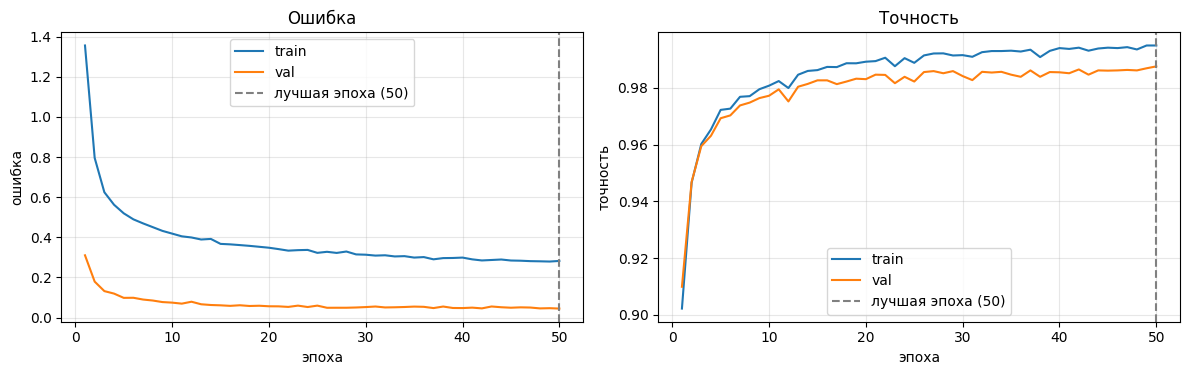

In [66]:
plot_history(history_Model_linear_1)

Модель Conv_1

In [67]:
conv_model_1, history_Model_Conv_1 = train_model(
    class_model = Model_Conv_1,
    learning_rate = 0.001,
    epochs = 50,
    train_default = train_4d,
    val_default = val_4d,
    test_default = test_4d,
    train = True,
    test = True,
    early_stopping = True,
    patience = 10,
    dynamic_lr = True,
    patience_lr = 5,
    seed = 2
    )

available device: cuda
Эпоха 1/50, train_accuracy: 0.9515, train_loss: 1.0115, accuracy_val: 0.9571,val_loss:0.1438, learning_rate: 0.001, время: 6.31 секунд
Эпоха 2/50, train_accuracy: 0.9701, train_loss: 0.5470, accuracy_val: 0.9721,val_loss:0.0943, learning_rate: 0.001, время: 7.75 секунд
Эпоха 3/50, train_accuracy: 0.9738, train_loss: 0.4569, accuracy_val: 0.9755,val_loss:0.0819, learning_rate: 0.001, время: 4.52 секунд
Эпоха 4/50, train_accuracy: 0.9810, train_loss: 0.4073, accuracy_val: 0.9826,val_loss:0.0605, learning_rate: 0.001, время: 4.53 секунд
Эпоха 5/50, train_accuracy: 0.9814, train_loss: 0.3774, accuracy_val: 0.9828,val_loss:0.0589, learning_rate: 0.001, время: 4.47 секунд
Эпоха 6/50, train_accuracy: 0.9839, train_loss: 0.3553, accuracy_val: 0.9844,val_loss:0.0533, learning_rate: 0.001, время: 4.51 секунд
Эпоха 7/50, train_accuracy: 0.9860, train_loss: 0.3313, accuracy_val: 0.9842,val_loss:0.0489, learning_rate: 0.001, время: 4.40 секунд
Эпоха 8/50, train_accuracy: 0.98

метрики для Conv_1

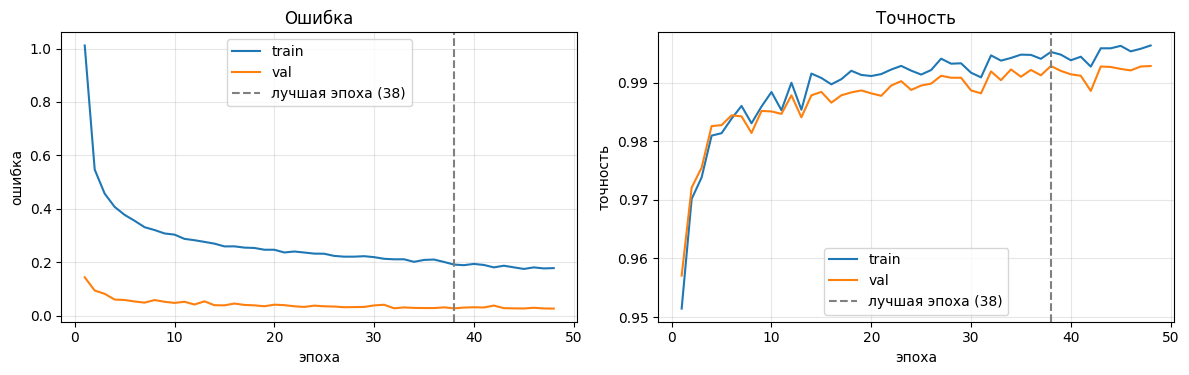

In [68]:
plot_history(history_Model_Conv_1)

Модель Conv_2

In [69]:
conv_model_2, history_Model_Conv_2 = train_model(
    class_model = Model_Conv_2,
    learning_rate = 0.001,
    epochs = 50,
    train_default = train_4d,
    val_default = val_4d,
    test_default = test_4d,
    train = True,
    test = True,
    early_stopping = True,
    patience = 10,
    dynamic_lr = True,
    patience_lr = 5,
    seed = 3
    )

available device: cuda
Эпоха 1/50, train_accuracy: 0.9566, train_loss: 1.1846, accuracy_val: 0.9589,val_loss:0.1286, learning_rate: 0.001, время: 4.89 секунд
Эпоха 2/50, train_accuracy: 0.9708, train_loss: 0.6366, accuracy_val: 0.9729,val_loss:0.0826, learning_rate: 0.001, время: 4.84 секунд
Эпоха 3/50, train_accuracy: 0.9751, train_loss: 0.5487, accuracy_val: 0.9768,val_loss:0.0725, learning_rate: 0.001, время: 4.81 секунд
Эпоха 4/50, train_accuracy: 0.9762, train_loss: 0.4922, accuracy_val: 0.9784,val_loss:0.0722, learning_rate: 0.001, время: 4.69 секунд
Эпоха 5/50, train_accuracy: 0.9827, train_loss: 0.4655, accuracy_val: 0.9833,val_loss:0.0539, learning_rate: 0.001, время: 4.77 секунд
Эпоха 6/50, train_accuracy: 0.9837, train_loss: 0.4415, accuracy_val: 0.9839,val_loss:0.0507, learning_rate: 0.001, время: 4.78 секунд
Эпоха 7/50, train_accuracy: 0.9861, train_loss: 0.4240, accuracy_val: 0.9858,val_loss:0.0449, learning_rate: 0.001, время: 4.82 секунд
Эпоха 8/50, train_accuracy: 0.98

Метрики для Conv_2

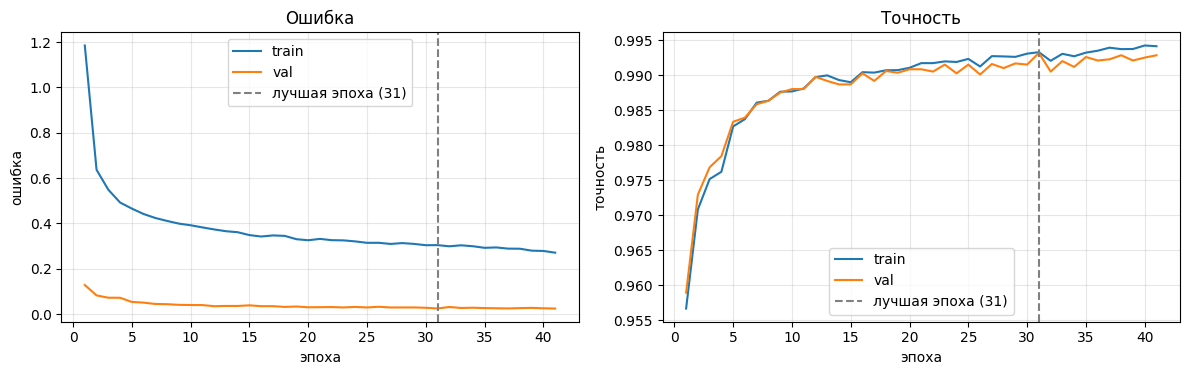

In [70]:
plot_history(history_Model_Conv_2)

Модель Conv_3

In [71]:
conv_model_3, history_Model_Conv_3 = train_model(
    class_model = Model_Conv_3,
    learning_rate = 0.001,
    epochs = 50,
    train_default = train_4d,
    val_default = val_4d,
    test_default = test_4d,
    train = True,
    test = True,
    early_stopping = True,
    patience = 10,
    dynamic_lr = True,
    patience_lr = 5,
    seed = 4
    )

available device: cuda
Эпоха 1/50, train_accuracy: 0.9546, train_loss: 1.2454, accuracy_val: 0.9594,val_loss:0.1349, learning_rate: 0.001, время: 5.34 секунд
Эпоха 2/50, train_accuracy: 0.9687, train_loss: 0.7416, accuracy_val: 0.9737,val_loss:0.0874, learning_rate: 0.001, время: 5.23 секунд
Эпоха 3/50, train_accuracy: 0.9742, train_loss: 0.6383, accuracy_val: 0.9781,val_loss:0.0709, learning_rate: 0.001, время: 4.82 секунд
Эпоха 4/50, train_accuracy: 0.9781, train_loss: 0.5846, accuracy_val: 0.9798,val_loss:0.0627, learning_rate: 0.001, время: 5.29 секунд
Эпоха 5/50, train_accuracy: 0.9805, train_loss: 0.5560, accuracy_val: 0.9837,val_loss:0.0561, learning_rate: 0.001, время: 4.86 секунд
Эпоха 6/50, train_accuracy: 0.9811, train_loss: 0.5250, accuracy_val: 0.9841,val_loss:0.0533, learning_rate: 0.001, время: 5.24 секунд
Эпоха 7/50, train_accuracy: 0.9830, train_loss: 0.5001, accuracy_val: 0.9848,val_loss:0.0499, learning_rate: 0.001, время: 4.88 секунд
Эпоха 8/50, train_accuracy: 0.98

Метрики для Conv_3

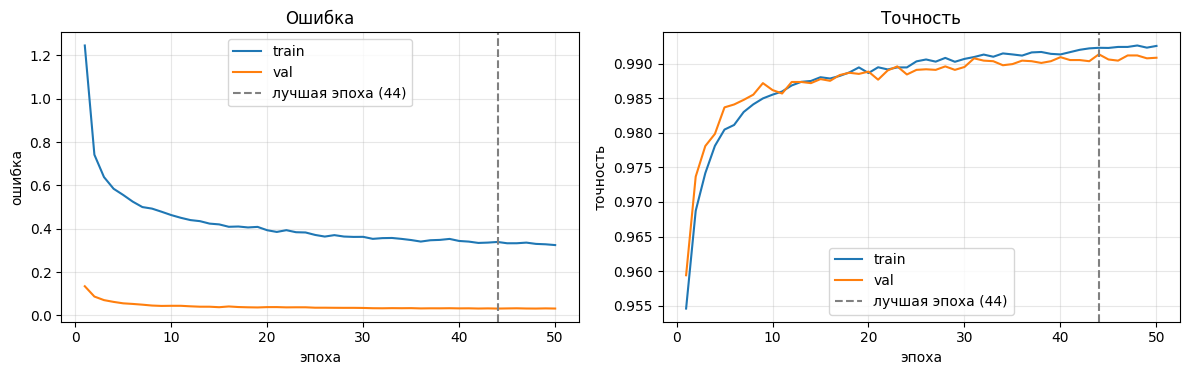

In [72]:
plot_history(history_Model_Conv_3)

модель 4

In [73]:
conv_model_4, history_Model_Conv_4 = train_model(
    class_model = Model_Conv_4,
    learning_rate = 0.001,
    epochs = 50,
    train_default = train_4d,
    val_default = val_4d,
    test_default = test_4d,
    train = True,
    test = True,
    early_stopping = True,
    patience = 10,
    dynamic_lr = True,
    patience_lr = 5,
    seed = 5
    )

available device: cuda
Эпоха 1/50, train_accuracy: 0.9584, train_loss: 1.1783, accuracy_val: 0.9621,val_loss:0.1273, learning_rate: 0.001, время: 5.00 секунд
Эпоха 2/50, train_accuracy: 0.9701, train_loss: 0.7077, accuracy_val: 0.9735,val_loss:0.0861, learning_rate: 0.001, время: 4.83 секунд
Эпоха 3/50, train_accuracy: 0.9749, train_loss: 0.6122, accuracy_val: 0.9780,val_loss:0.0711, learning_rate: 0.001, время: 4.96 секунд
Эпоха 4/50, train_accuracy: 0.9804, train_loss: 0.5606, accuracy_val: 0.9825,val_loss:0.0586, learning_rate: 0.001, время: 4.89 секунд
Эпоха 5/50, train_accuracy: 0.9823, train_loss: 0.5206, accuracy_val: 0.9847,val_loss:0.0530, learning_rate: 0.001, время: 4.95 секунд
Эпоха 6/50, train_accuracy: 0.9829, train_loss: 0.4967, accuracy_val: 0.9842,val_loss:0.0533, learning_rate: 0.001, время: 5.09 секунд
Эпоха 7/50, train_accuracy: 0.9845, train_loss: 0.4794, accuracy_val: 0.9858,val_loss:0.0482, learning_rate: 0.001, время: 4.94 секунд
Эпоха 8/50, train_accuracy: 0.98

Метрики для Conv_4

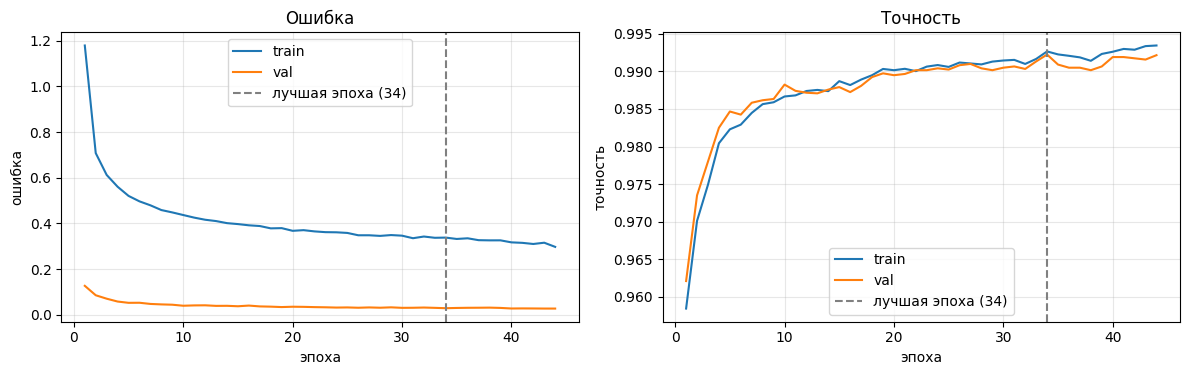

In [74]:
plot_history(history_Model_Conv_4)

функция вывода примера батча с предсказанием модели

In [75]:
def show_predictions(model, data, targets, n=10):
    # n случайных картинок
    idx = torch.randperm(len(data))[:n]
    images = data[idx]
    labels = targets[idx]

    model.to(device)
    model.eval()
    with torch.no_grad():
        preds = model(images.to(device)).argmax(dim=1).cpu()

    cols = 5
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    axes = axes.flatten()

    for ax in axes:
        ax.axis('off')

    for ax, img, label, pred in zip(axes, images, labels, preds):
        ax.imshow(img.view(28, 28), cmap='gray')
        # большая белая цифра в правом нижнем углу
        ax.text(
            0.95, 0.05, str(pred.item()),
            transform=ax.transAxes,
            ha='right', va='bottom',
            color='white', fontsize=26, fontweight='bold',
        )
        ax.set_title(f"верно: {label.item()}", fontsize=10)

    plt.tight_layout()
    plt.show()

вызов для линейной

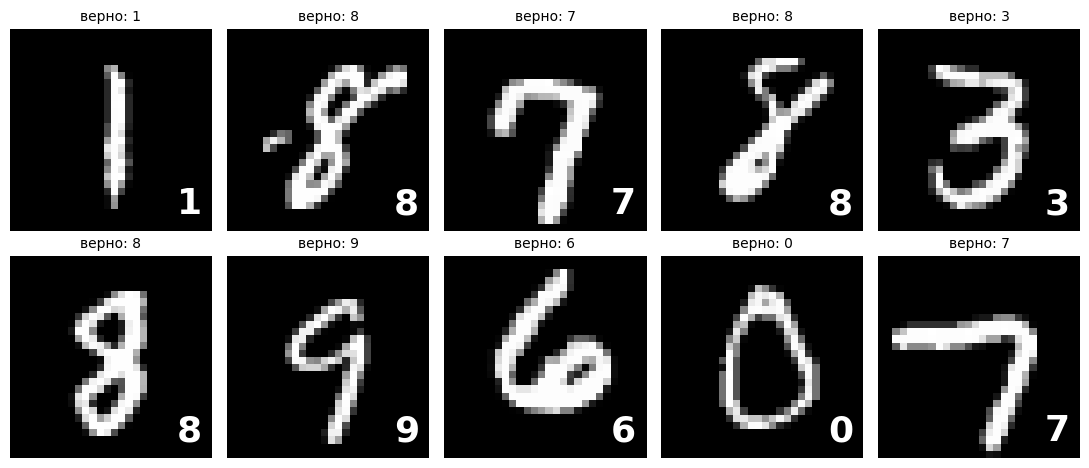

In [76]:
show_predictions(linear_model, test_4d, tensor_test_target)

вызов для Conv_1

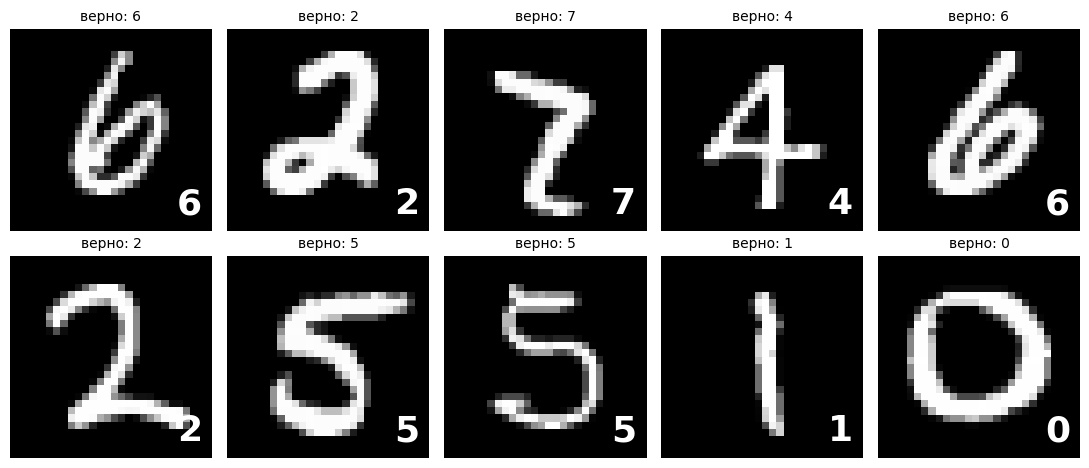

In [77]:
show_predictions(conv_model_1, test_4d, tensor_test_target)

вызов для Conv_2

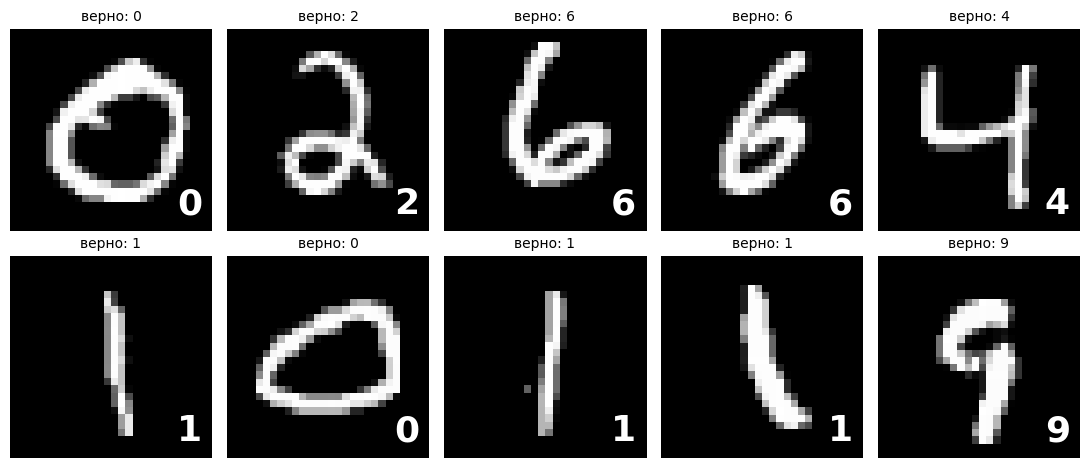

In [78]:
show_predictions(conv_model_2, test_4d, tensor_test_target)

вызов для Conv_3

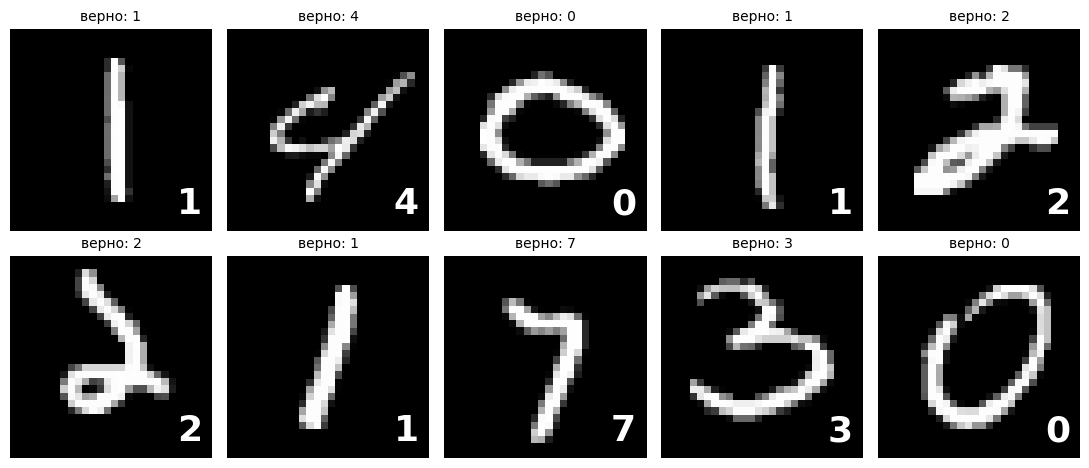

In [79]:
show_predictions(conv_model_3, test_4d, tensor_test_target)

вызов для Conv_4

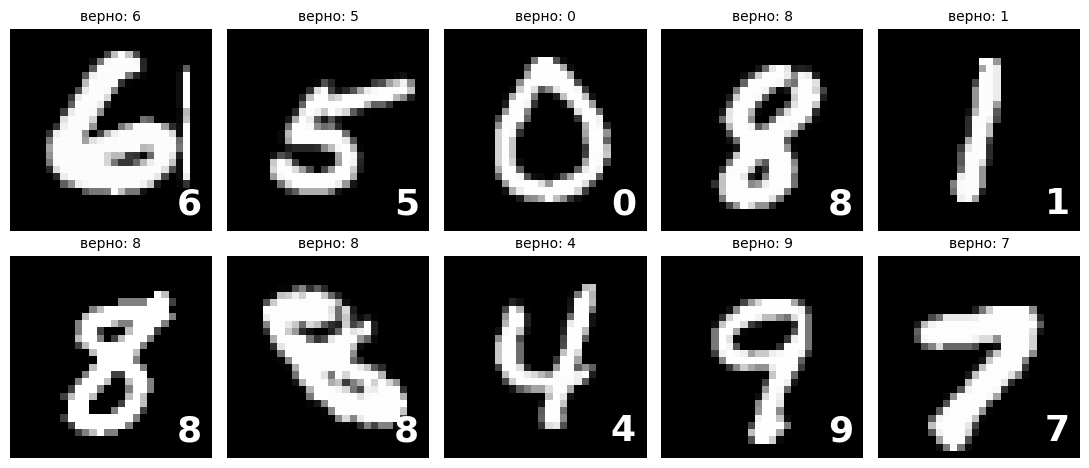

In [80]:
show_predictions(conv_model_4, test_4d, tensor_test_target)

функция ансамбль для всех моделей

In [96]:
def ensemble_predict(data, targets, batch_size=256):
    models = [conv_model_1, conv_model_2, conv_model_3, conv_model_4]

    loader = DataLoader(MyDataset(data, targets), batch_size=batch_size, shuffle=False)

    for model in models:
        model.to(device)
        model.eval()

    all_preds = []
    correct_each = [0] * 4
    correct, count = 0, 0

    with torch.no_grad():
        for images, labels in loader:   #тоже самое что с лоадером в общей функции обучения
            images = images.to(device)
            labels = labels.to(device)

            probs_sum = torch.zeros(len(labels), 10, device=device)
            for i, model in enumerate(models):
                probs = torch.softmax(model(images), dim=1)
                probs_sum += probs
                correct_each[i] += (probs.argmax(dim=1) == labels).sum().item()

            probs_mean = probs_sum / 4    #делим на число моделей
            preds = probs_mean.argmax(dim=1)

            correct += (preds == labels).sum().item()
            count += len(labels)
            all_preds.append(preds.cpu())

    for i, c in enumerate(correct_each):
        print(f"модель {i + 1}: {c / count:.4f}")
    print(f"ансамбль:  {correct / count:.4f}")

    return torch.cat(all_preds)

ensemble_preds = ensemble_predict(test_4d, tensor_test_target)

модель 1: 0.9938
модель 2: 0.9928
модель 3: 0.9937
модель 4: 0.9932
ансамбль:  0.9953


In [ ]:
скачиваем каждую модель с весами

In [100]:
from google.colab import files
models = {
    "conv_model_1": conv_model_1,
    "conv_model_2": conv_model_2,
    "conv_model_3": conv_model_3,
    "conv_model_4": conv_model_4,
}

for name, model in models.items():
    path = f"{name}.pt"
    torch.save(model.state_dict(), path)
    files.download(path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

скачиваем ансамбль

In [103]:
class Ensemble(nn.Module):
    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)   # ModuleList, чтобы веса попали в state_dict

    def forward(self, x):
        probs = torch.stack([torch.softmax(m(x), dim=1) for m in self.models])
        return probs.mean(dim=0)              # усреднённые вероятности

ensemble = Ensemble([conv_model_1, conv_model_2, conv_model_3, conv_model_4])
ensemble.to(device).eval()

ensemble.cpu().eval()
example = torch.zeros(1, 1, 28, 28)
scripted = torch.jit.trace(ensemble, example)
scripted.save("ensemble.pt")
files.download("ensemble.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>